# 03 - Logistic Regression Model

## HIGGS Boson Signal Detection

This notebook implements Logistic Regression as the baseline
classification model using the preprocessed HIGGS dataset.

### Objectives
- Load the preprocessed training and validation datasets.
- Train a Logistic Regression classifier.
- Evaluate classification performance.
- Save the trained model and evaluation results.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 1. Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.model_selection import GridSearchCV

In [3]:
import os

BASE_PATH = "/content/drive/MyDrive/Higgs-boson-signal-detection-ML"

print("Files in project folder:")

for item in os.listdir(BASE_PATH):
    print(item)

Files in project folder:
data
reports
models
notebooks


In [4]:
DATA_PATH = os.path.join(BASE_PATH, "data")

for root, dirs, files in os.walk(DATA_PATH):
    print(f"\nFolder: {root}")

    for file in files:
        print("  ", file)


Folder: /content/drive/MyDrive/Higgs-boson-signal-detection-ML/data

Folder: /content/drive/MyDrive/Higgs-boson-signal-detection-ML/data/raw
   HIGGS.csv.gz

Folder: /content/drive/MyDrive/Higgs-boson-signal-detection-ML/data/processed
   train.parquet
   validation.parquet
   test.parquet
   train_scaled.parquet
   validation_scaled.parquet
   test_scaled.parquet


## 2. Load Preprocessed Data

The scaled training and validation datasets are loaded for Logistic Regression model development.

In [5]:
PROCESSED_PATH = os.path.join(BASE_PATH, "data", "processed")

train_df = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "train_scaled.parquet")
)

val_df = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "validation_scaled.parquet")
)

print("Training Dataset:", train_df.shape)
print("Validation Dataset:", val_df.shape)

display(train_df.head())

Training Dataset: (7504911, 29)
Validation Dataset: (1608195, 29)


,lepton_pT,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet1_pT,jet1_eta,jet1_phi,jet1_b_tag,jet2_pT,...,jet4_phi,jet4_b_tag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb,target
0,0.773799,0.956005,0.741924,0.124044,0.083994,-0.250272,1.390878,-1.328347,1.141734,-0.858756,...,1.687177,-0.714680,-0.330591,-0.179900,-0.384504,-0.703252,-0.459692,-0.534914,-0.744150,1
1,0.605651,1.149135,0.353737,1.828505,0.609622,0.881351,-0.441824,-1.559309,-0.972615,0.835387,...,1.148621,1.500142,0.575880,0.030041,-0.351562,2.365544,0.931463,2.135467,3.078417,1
2,0.245982,0.837230,1.029205,-0.567544,-1.337579,-0.818011,0.982739,0.272511,1.141734,-0.539719,...,-1.668841,-0.714680,-0.743868,-0.736312,-0.295616,-0.575442,-0.135432,-0.305829,-0.067146,0
3,-0.067916,0.315779,-0.774536,-0.408259,-0.270266,2.281709,1.038662,1.125254,-0.972615,2.242221,...,0.983802,-0.714680,0.229090,-0.062746,-0.403639,-0.900977,-0.783281,-1.139860,-1.114997,1
4,1.160084,-0.462536,-0.931134,-0.411427,-0.098154,0.012488,-0.033685,1.159429,1.141734,-0.504215,...,-0.027814,-0.714680,-0.509822,-0.613161,0.032342,0.072939,-0.172861,-0.158147,-0.623020,1


## 3. Feature and Target Separation

The 28 input features and binary target variable are separated for model training and validation.

In [6]:
X_train = train_df.drop(columns=["target"])
y_train = train_df["target"]

X_val = val_df.drop(columns=["target"])
y_val = val_df["target"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (7504911, 28)
y_train: (7504911,)
X_val: (1608195, 28)
y_val: (1608195,)


## 4. Logistic Regression Model Training

A Logistic Regression model is trained using the scaled training dataset as a baseline classifier.

In [7]:
import time

# Initialize Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    random_state=42
)

# Train the model
start_time = time.time()

lr_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Logistic Regression training completed!")
print(f"Training Time: {training_time:.2f} seconds")
print(f"Iterations Used: {lr_model.n_iter_[0]}")

Logistic Regression training completed!
Training Time: 40.46 seconds
Iterations Used: 17


## 5. Model Predictions

The trained model is used to predict class labels and signal probabilities on the validation dataset.

In [8]:
# Predict class labels
y_val_pred = lr_model.predict(X_val)

# Predict signal probabilities
y_val_prob = lr_model.predict_proba(X_val)[:, 1]

print("Predictions completed!")

print("Predicted Classes:", y_val_pred[:10])
print("Signal Probabilities:", y_val_prob[:10])

Predictions completed!
Predicted Classes: [1 1 1 0 1 1 1 1 0 0]
Signal Probabilities: [0.5313936  0.62122434 0.53840624 0.30825652 0.58060525 0.58315675
 0.60855422 0.72308559 0.13353883 0.47975224]


## 6. Model Evaluation

The Logistic Regression model is evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, PR-AUC, and Log Loss.

In [9]:
# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_val, y_val_pred)
lr_precision = precision_score(y_val, y_val_pred)
lr_recall = recall_score(y_val, y_val_pred)
lr_f1 = f1_score(y_val, y_val_pred)
lr_roc_auc = roc_auc_score(y_val, y_val_prob)
lr_pr_auc = average_precision_score(y_val, y_val_prob)
lr_log_loss = log_loss(y_val, y_val_prob)

# Display results
print("Logistic Regression - Validation Results")
print("-" * 45)

print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1-score  : {lr_f1:.4f}")
print(f"ROC-AUC   : {lr_roc_auc:.4f}")
print(f"PR-AUC    : {lr_pr_auc:.4f}")
print(f"Log Loss  : {lr_log_loss:.4f}")

Logistic Regression - Validation Results
---------------------------------------------
Accuracy  : 0.6449
Precision : 0.6444
Recall    : 0.7739
F1-score  : 0.7033
ROC-AUC   : 0.6840
PR-AUC    : 0.6947
Log Loss  : 0.6359


## 7. Confusion Matrix

The confusion matrix shows correct and incorrect predictions for background and signal events.

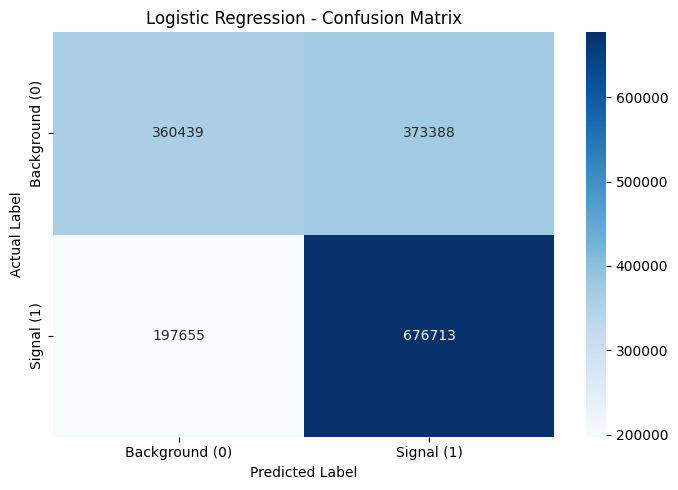

In [10]:
# Calculate confusion matrix
lr_cm = confusion_matrix(y_val, y_val_pred)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Background (0)", "Signal (1)"],
    yticklabels=["Background (0)", "Signal (1)"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

## 8. ROC Curve

The ROC curve evaluates the model's ability to distinguish between signal and background events at different classification thresholds.

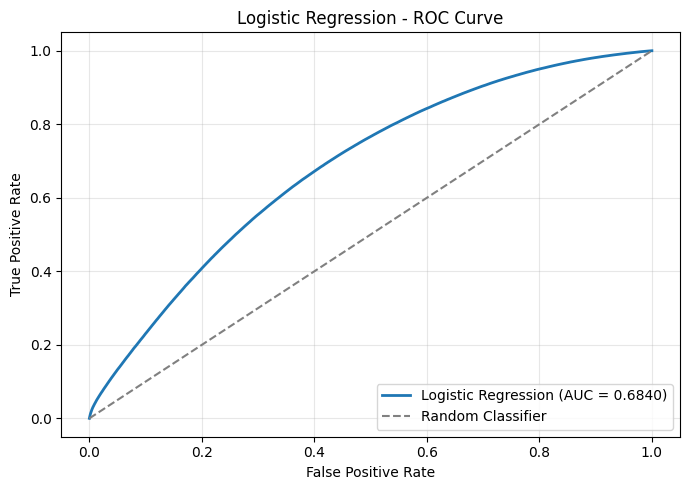

In [11]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)

# Calculate AUC
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Precision-Recall Curve

The Precision-Recall curve evaluates the model's ability to identify signal events while minimizing false positives.

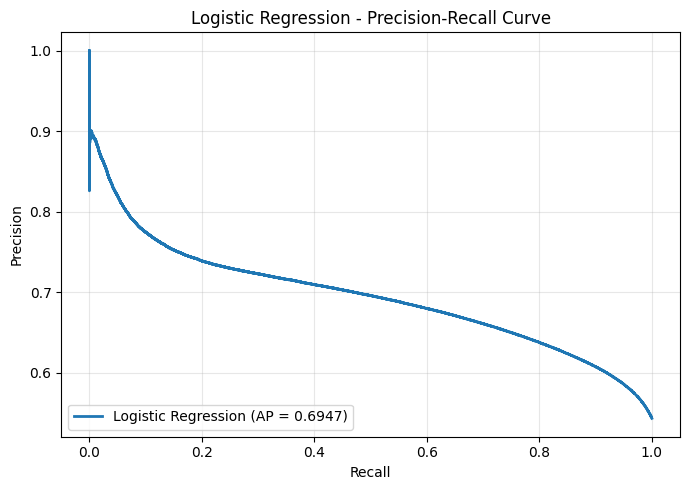

In [12]:
from sklearn.metrics import precision_recall_curve

# Calculate Precision-Recall curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

# Plot Precision-Recall curve
plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"Logistic Regression (AP = {lr_pr_auc:.4f})",
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression - Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Classification Report

The classification report provides Precision, Recall, F1-score, and Support for each class.

In [14]:
# Generate classification report
lr_report = classification_report(
    y_val,
    y_val_pred,
    target_names=["Background (0)", "Signal (1)"],
    digits=4
)

print("Logistic Regression - Classification Report")
print("-" * 50)
print(lr_report)

Logistic Regression - Classification Report
--------------------------------------------------
                precision    recall  f1-score   support

Background (0)     0.6458    0.4912    0.5580    733827
    Signal (1)     0.6444    0.7739    0.7033    874368

      accuracy                         0.6449   1608195
     macro avg     0.6451    0.6326    0.6306   1608195
  weighted avg     0.6451    0.6449    0.6370   1608195



## 11. Save Baseline Model and Results

The trained baseline model and validation metrics are saved for future evaluation and model comparison.

In [15]:
# Create output directories
MODEL_PATH = os.path.join(BASE_PATH, "models", "logistic_regression")
REPORT_PATH = os.path.join(BASE_PATH, "reports", "logistic_regression")

os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

# Save trained model
joblib.dump(
    lr_model,
    os.path.join(MODEL_PATH, "logistic_regression_baseline.joblib")
)

# Save evaluation metrics
lr_results = pd.DataFrame([{
    "Model": "Logistic Regression Baseline",
    "Accuracy": lr_accuracy,
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1-score": lr_f1,
    "ROC-AUC": lr_roc_auc,
    "PR-AUC": lr_pr_auc,
    "Log Loss": lr_log_loss,
    "Training Time (s)": training_time
}])

lr_results.to_csv(
    os.path.join(REPORT_PATH, "baseline_metrics.csv"),
    index=False
)

# Save classification report
with open(
    os.path.join(REPORT_PATH, "classification_report.txt"),
    "w"
) as f:
    f.write(lr_report)

print("Baseline model and results saved successfully!")
display(lr_results)

Baseline model and results saved successfully!


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Log Loss,Training Time (s)
0,Logistic Regression Baseline,0.644917,0.644427,0.773945,0.703272,0.683953,0.69472,0.635949,40.45614


## 12. Hyperparameter Tuning

A stratified sample of the training dataset is used to tune Logistic Regression hyperparameters efficiently.

In [16]:
from sklearn.model_selection import train_test_split

# Select 500,000 training records for tuning
X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    stratify=y_train,
    random_state=42
)

print("Tuning Features:", X_tune.shape)
print("Tuning Labels:", y_tune.shape)

print("\nClass Distribution:")
print(y_tune.value_counts(normalize=True))

Tuning Features: (500000, 28)
Tuning Labels: (500000,)

Class Distribution:
target
1    0.543696
0    0.456304
Name: proportion, dtype: float64


## 13. Hyperparameter Search

GridSearchCV is used with 5-fold stratified cross-validation to identify the best regularization parameter for Logistic Regression.

In [17]:
# Define parameter grid
param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10]
}

# Initialize Logistic Regression
lr_tuning_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

# Configure GridSearchCV
lr_grid_search = GridSearchCV(
    estimator=lr_tuning_model,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=2,
    verbose=1
)

# Run hyperparameter search
start_time = time.time()

lr_grid_search.fit(X_tune, y_tune)

tuning_time = time.time() - start_time

print("\nHyperparameter Tuning Completed!")
print("Best Parameters:", lr_grid_search.best_params_)
print(f"Best CV ROC-AUC: {lr_grid_search.best_score_:.4f}")
print(f"Tuning Time: {tuning_time:.2f} seconds")

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Hyperparameter Tuning Completed!
Best Parameters: {'C': 10}
Best CV ROC-AUC: 0.6829
Tuning Time: 43.90 seconds


## 14. Hyperparameter Tuning Results

Cross-validation ROC-AUC scores are compared to evaluate different regularization strengths.

In [21]:
# Extract GridSearchCV results
tuning_results = pd.DataFrame(
    lr_grid_search.cv_results_
)

# Select important columns
tuning_summary = tuning_results[
    ["param_C", "mean_test_score", "std_test_score", "rank_test_score"]
].copy()

# Rename columns
tuning_summary.columns = [
    "C",
    "Mean ROC-AUC",
    "Std ROC-AUC",
    "Rank"
]

# Sort by C value
tuning_summary = tuning_summary.sort_values("C")

display(tuning_summary)

,C,Mean ROC-AUC,Std ROC-AUC,Rank
0,0.001,0.681307,0.000799,5
1,0.010,0.682758,0.000813,4
2,0.100,0.682910,0.000814,3
3,1.000,0.682925,0.000814,2
4,10.000,0.682927,0.000814,1


## 15. Hyperparameter Tuning Visualization

The relationship between the regularization parameter C and cross-validation ROC-AUC is visualized.

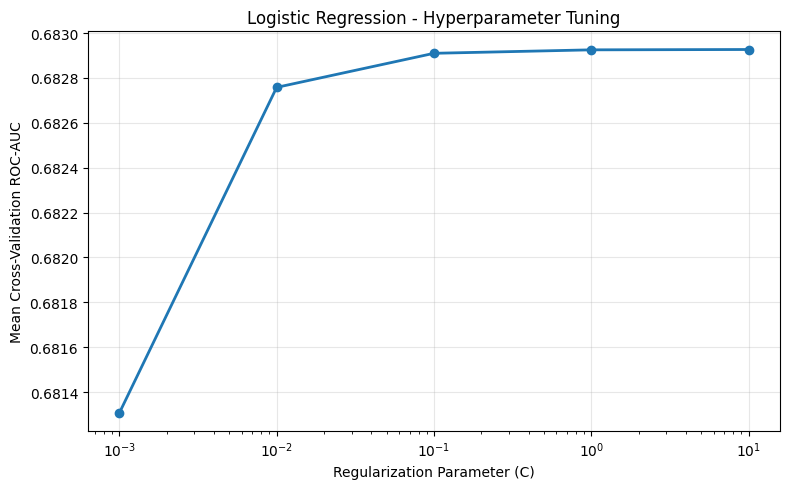

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    tuning_summary["C"],
    tuning_summary["Mean ROC-AUC"],
    marker="o",
    linewidth=2
)

plt.xscale("log")

plt.xlabel("Regularization Parameter (C)")
plt.ylabel("Mean Cross-Validation ROC-AUC")
plt.title("Logistic Regression - Hyperparameter Tuning")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Tuned Logistic Regression Model

The Logistic Regression model is retrained on the full training dataset using the best hyperparameter identified through cross-validation.

In [23]:
# Initialize tuned Logistic Regression
lr_tuned_model = LogisticRegression(
    C=lr_grid_search.best_params_["C"],
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

# Train tuned model
start_time = time.time()

lr_tuned_model.fit(X_train, y_train)

tuned_training_time = time.time() - start_time

print("Tuned Logistic Regression training completed!")
print("Best C:", lr_tuned_model.C)
print(f"Training Time: {tuned_training_time:.2f} seconds")
print(f"Iterations Used: {lr_tuned_model.n_iter_[0]}")

Tuned Logistic Regression training completed!
Best C: 10
Training Time: 30.08 seconds
Iterations Used: 17


## 17. Baseline vs Tuned Model Comparison

The baseline and tuned Logistic Regression models are evaluated on the same validation dataset to compare their performance.

In [24]:
# Generate tuned model predictions
y_val_pred_tuned = lr_tuned_model.predict(X_val)
y_val_prob_tuned = lr_tuned_model.predict_proba(X_val)[:, 1]

# Calculate tuned model metrics
tuned_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_val_pred_tuned),
    "Precision": precision_score(y_val, y_val_pred_tuned),
    "Recall": recall_score(y_val, y_val_pred_tuned),
    "F1-score": f1_score(y_val, y_val_pred_tuned),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob_tuned),
    "PR-AUC": average_precision_score(y_val, y_val_prob_tuned),
    "Log Loss": log_loss(y_val, y_val_prob_tuned),
    "Training Time (s)": tuned_training_time
}

# Combine baseline and tuned results
comparison_df = pd.concat(
    [
        lr_results,
        pd.DataFrame([tuned_results])
    ],
    ignore_index=True
)

# Display comparison
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Log Loss,Training Time (s)
0,Logistic Regression Baseline,0.6449,0.6444,0.7739,0.7033,0.684,0.6947,0.6359,40.4561
1,Tuned Logistic Regression,0.6449,0.6444,0.7739,0.7033,0.684,0.6947,0.6359,30.0834


## 18. Final Model Selection

The baseline and tuned models are compared using validation ROC-AUC. The simpler baseline model is preferred when performance differences are negligible.

In [25]:
# Compare exact validation ROC-AUC scores
baseline_auc = lr_roc_auc
tuned_auc = tuned_results["ROC-AUC"]

print(f"Baseline ROC-AUC: {baseline_auc:.8f}")
print(f"Tuned ROC-AUC   : {tuned_auc:.8f}")
print(f"Difference      : {tuned_auc - baseline_auc:.8f}")

# Select model
tolerance = 0.0001

if tuned_auc - baseline_auc > tolerance:
    final_lr_model = lr_tuned_model
    selected_model_name = "Tuned Logistic Regression"
else:
    final_lr_model = lr_model
    selected_model_name = "Baseline Logistic Regression"

print("\nSelected Model:", selected_model_name)
print("Selected C:", final_lr_model.C)

Baseline ROC-AUC: 0.68395316
Tuned ROC-AUC   : 0.68395324
Difference      : 0.00000008

Selected Model: Baseline Logistic Regression
Selected C: 1.0


## 19. Final Model Evaluation on Test Data

The selected Logistic Regression model is evaluated on the unseen test dataset to measure its generalization performance.

In [34]:
# Load scaled test dataset
test_df = pd.read_parquet(
    os.path.join(PROCESSED_PATH, "test_scaled.parquet")
)

# Separate features and target
X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

print("Test Features:", X_test.shape)
print("Test Labels:", y_test.shape)

# Generate predictions
y_test_pred = final_lr_model.predict(X_test)
y_test_prob = final_lr_model.predict_proba(X_test)[:, 1]

# Calculate test metrics
lr_test_results = {
    "Model": selected_model_name,
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1-score": f1_score(y_test, y_test_pred),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
    "PR-AUC": average_precision_score(y_test, y_test_prob),
    "Log Loss": log_loss(y_test, y_test_prob)
}

test_results_df = pd.DataFrame([lr_test_results])

print("\nFinal Logistic Regression Test Results")
display(test_results_df.round(6))

Test Features: (1608196, 28)
Test Labels: (1608196,)

Final Logistic Regression Test Results


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Log Loss
0,Baseline Logistic Regression,0.645587,0.645018,0.774238,0.703745,0.684784,0.695657,0.635498


## 20. Save Final Model and Test Results

The selected Logistic Regression model and its final test evaluation metrics are saved for reproducibility and comparison with other machine learning algorithms.

In [35]:
import os
import joblib

# Create directories
MODEL_PATH = os.path.join(
    BASE_PATH, "models", "logistic_regression"
)

REPORT_PATH = os.path.join(
    BASE_PATH, "reports", "logistic_regression"
)

os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

# Save final trained model
joblib.dump(
    final_lr_model,
    os.path.join(MODEL_PATH, "logistic_regression_final.joblib")
)

# Save final test metrics
test_results_df.to_csv(
    os.path.join(REPORT_PATH, "test_metrics.csv"),
    index=False
)

# Save model comparison
comparison_df.to_csv(
    os.path.join(REPORT_PATH, "validation_model_comparison.csv"),
    index=False
)

print("Final Logistic Regression model saved successfully!")
print("Test metrics saved successfully!")
print("Validation comparison saved successfully!")

Final Logistic Regression model saved successfully!
Test metrics saved successfully!
Validation comparison saved successfully!


## 21. Final Test Confusion Matrix

The confusion matrix visualizes the classification performance of the selected Logistic Regression model on the unseen test dataset.

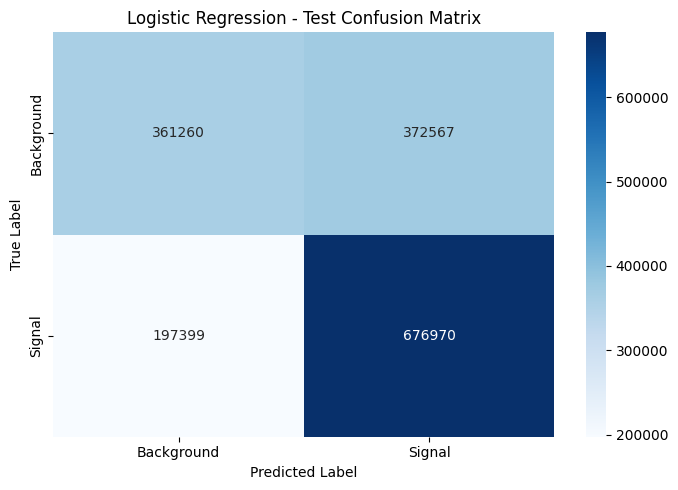

True Negatives: 361260
False Positives: 372567
False Negatives: 197399
True Positives: 676970


In [36]:
# Calculate test confusion matrix
cm_test = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Background", "Signal"],
    yticklabels=["Background", "Signal"]
)

plt.title("Logistic Regression - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

# Save graph
plt.savefig(
    os.path.join(REPORT_PATH, "test_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print confusion matrix values
tn, fp, fn, tp = cm_test.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)b

## 22. Final Test ROC Curve

The ROC curve evaluates the model's ability to distinguish between Higgs signal and background events using the unseen test dataset.

<Figure size 800x600 with 0 Axes>

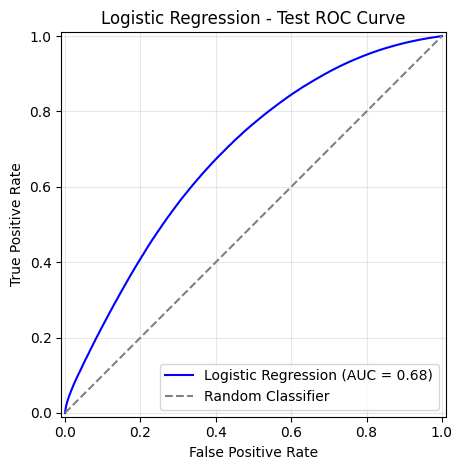

Test ROC-AUC: 0.684784


In [37]:
# Plot ROC Curve using test dataset
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob,
    name="Logistic Regression",
    color="blue"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("Logistic Regression - Test ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save ROC Curve
plt.savefig(
    os.path.join(REPORT_PATH, "test_roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Test ROC-AUC: {lr_test_results['ROC-AUC']:.6f}")

## 23. Final Test Precision-Recall Curve

The Precision-Recall curve evaluates the model's ability to identify Higgs signal events across different classification thresholds.

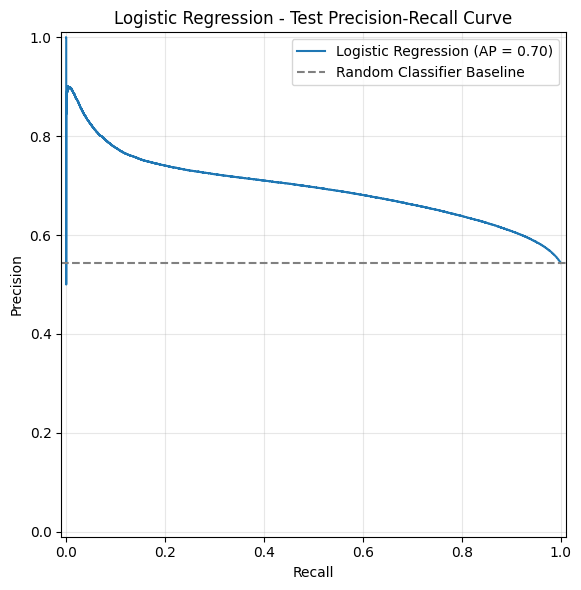

Test Average Precision: 0.695657


In [38]:
# Plot Precision-Recall Curve
fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob,
    name="Logistic Regression",
    ax=ax
)

# Baseline: positive class proportion
positive_rate = y_test.mean()

ax.axhline(
    y=positive_rate,
    color="gray",
    linestyle="--",
    label="Random Classifier Baseline"
)

ax.set_title("Logistic Regression - Test Precision-Recall Curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# Save graph
plt.savefig(
    os.path.join(REPORT_PATH, "test_precision_recall_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Test Average Precision: {lr_test_results['PR-AUC']:.6f}")

## 24. Final Test Classification Report

The classification report presents precision, recall, F1-score, and support for both background and Higgs signal events on the unseen test dataset.

In [40]:
# Generate final test classification report
lr_test_report = classification_report(
    y_test,
    y_test_pred,
    target_names=["Background (0)", "Signal (1)"],
    digits=4
)

# Display report
print("Final Logistic Regression Classification Report")
print(lr_test_report)

# Save report
report_file = os.path.join(
    REPORT_PATH,
    "test_classification_report.txt"
)

with open(report_file, "w") as f:
    f.write(lr_test_report)

print("\nClassification report saved successfully!")
print("Saved to:", report_file)

Final Logistic Regression Classification Report
                precision    recall  f1-score   support

Background (0)     0.6467    0.4923    0.5590    733827
    Signal (1)     0.6450    0.7742    0.7037    874369

      accuracy                         0.6456   1608196
     macro avg     0.6458    0.6333    0.6314   1608196
  weighted avg     0.6458    0.6456    0.6377   1608196


Classification report saved successfully!
Saved to: /content/drive/MyDrive/Higgs-boson-signal-detection-ML/reports/logistic_regression/test_classification_report.txt


## 25. Logistic Regression - Final Summary

- **Dataset:** HIGGS Particle Collision Dataset (11 million records)
- **Features:** 28 numerical features
- **Algorithm:** Logistic Regression
- **Hyperparameter Tuning:** 5-Fold Cross-Validation using C values
- **Selected Model:** Baseline Logistic Regression (C = 1)
- **Test Accuracy:** 64.56%
- **Test Precision:** 64.50%
- **Test Recall:** 77.42%
- **Test F1-score:** 70.37%
- **Test ROC-AUC:** 0.6848
- **Test PR-AUC:** 0.6957
- **Test Log Loss:** 0.6355

### Conclusion

Logistic Regression achieved moderate classification performance on the HIGGS dataset. Hyperparameter tuning produced negligible improvement. The model demonstrated similar validation and test performance, providing a baseline for comparison with more complex machine learning algorithms.